# Notebook 07: Uncertainty and the thresholds we choose

**Goal (two or three sessions):** put error bars on the pooled results and, just as important, measure how much the results depend on the pre-processing gates and post-processing thresholds in the pipeline. The idea to take away: *a result is the measurement plus the choices that produced it; benchmark both.*

Four sources of uncertainty, from smallest to largest in practice:

1. **Formal** error on each measurement (from the misfit surface; `phi_error`, `dt_error`).
2. **Sampling** error on the pooled mean (bootstrap).
3. **Threshold** sensitivity: what happens to N, mean phi and mean dt when the post-processing cuts and pre-gates move.
4. **Processing** sensitivity: what happens to a single measurement when the pick, windows or filter move.

> **Note on STAR.** STAR's vertical and north channels are exchanged in the archive (notebook 02). The original results file (`sws_star_strict_results.csv`) was computed on the channels as labelled, so the "horizontals" the pipeline used were really the vertical and east records. This notebook uses the research pipeline's re-run instead (`sws_star_strict_oriented_results.csv`, read with `paths.station_results_csv("STAR", oriented=True)`): the same pipeline, incidence angles and parameters on waveforms rotated to true Z/N/E, with the 33 events whose S wave clipped removed (stage `fail_clipped`). With the post-processing filter (Q_w ≥ 0.75, the research repo's current cut) it keeps 194 events instead of 110, only 44 of them in common. The pre-fix east-west cluster next to the back azimuth (66 of the 110 fast directions between 80 and 100 degrees) is gone; the corrected fast directions cluster north-north-east, 136 of the 194 between 20 and 40 degrees, with a mean of 34 degrees and R = 0.86, the numbers in the research repo's figures. The measurement is deterministic but sensitive to its input: adding noise of a billionth of a count to the corrected waveforms changes Q_w for about one measured event in 25. RCM and MILD are oriented as their metadata say, and their results did not change. The VT background in exercise 1 has not been re-run, so it is compared with the pre-fix swarm.

In [1]:
# --- setup: make the repo importable and keep figures inline ---
import sys, warnings
from pathlib import Path
REPO = Path.cwd().parent if (Path.cwd() / "../rainier_sws").exists() else Path.cwd()
sys.path.insert(0, str(REPO))
warnings.filterwarnings("ignore")
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
from rainier_sws import paths, data, measure, quality, stats
print("repo:", REPO)

repo: /Users/mhemmett/Seismology/rainier-sws-tutorials


In [2]:
STATIONS = ["STAR", "RCM", "MILD"]
# STAR from the research re-run on true Z/N/E with clipped events removed (oriented=True);
# RCM and MILD are oriented as their metadata say, and their results did not change
res = {s: pd.read_csv(paths.station_results_csv(s, oriented=(s == "STAR"))) for s in STATIONS}

## 1. Formal errors: are they believable?

The formal errors say how wide the misfit valley is. In notebook 04 you saw that at low SNR the *actual* error can be larger than the valley width suggests. Compare the distribution of reported errors with SNR and with Q_w.

phi_error: rank correlation with SNR +0.03 (p = 0.47), N = 659
dt_error: rank correlation with SNR +0.05 (p = 0.23), N = 659
dt_error at its floor of 0.01 s: 321; phi_error of 89 degrees or more (the region fills the grid): 62


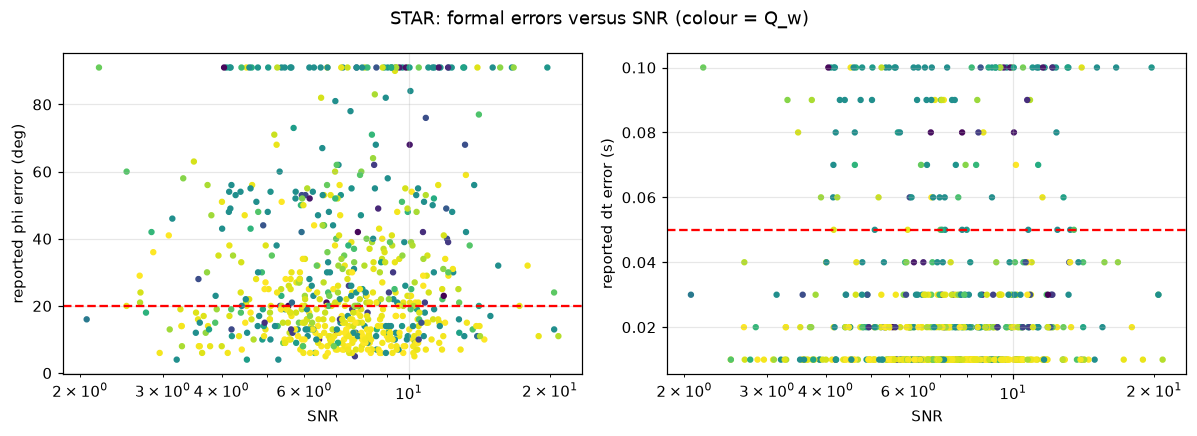

In [3]:
ok = quality.successful(res["STAR"])
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(ok.snr_horizontal, ok.phi_error, s=10, c=ok.quality, cmap="viridis"); axes[0].set_xscale("log")
axes[0].set_xlabel("SNR"); axes[0].set_ylabel("reported phi error (deg)"); axes[0].axhline(quality.DEFAULT_POST.phi_error_max, color="r", ls="--")
axes[1].scatter(ok.snr_horizontal, ok.dt_error, s=10, c=ok.quality, cmap="viridis"); axes[1].set_xscale("log")
axes[1].set_xlabel("SNR"); axes[1].set_ylabel("reported dt error (s)"); axes[1].axhline(quality.DEFAULT_POST.dt_error_max, color="r", ls="--")
fig.suptitle("STAR: formal errors versus SNR (colour = Q_w)"); plt.tight_layout()

from scipy.stats import spearmanr
for col in ("phi_error", "dt_error"):
    rho, p = spearmanr(ok.snr_horizontal, ok[col])
    print(f"{col}: rank correlation with SNR {rho:+.2f} (p = {p:.2f}), N = {len(ok)}")
print(f"dt_error at its floor of {ok.dt_error.min():g} s: {(ok.dt_error == ok.dt_error.min()).sum()}; "
      f"phi_error of 89 degrees or more (the region fills the grid): {(ok.phi_error >= 89).sum()}")

The formal errors hardly depend on SNR at all (the rank correlations printed above are close to zero). They are not an error bar that shrinks with noise: SWSPy reports the half-width of the region of the misfit surface inside a 99.7 percent (3-sigma) F-test confidence level, on a grid of 2 degrees and 0.02 s. So dt_error bottoms out at 0.01 s, half a grid step, for about half the measurements, and phi_error tops out near 90 degrees when the region fills the grid. Note also the many low-SNR measurements with *small* reported errors: a narrow valley in a noisy surface. This is why the pipeline requires SNR and Q_w as well as small errors. A proper calibration (synthetic events pushed through the full SWSPy pipeline, as notebook 04 did with the toy version) is a good stretch project; the exercise at the end sets it up.

## 2. Sampling error: bootstrap intervals on the pooled result

Resample the filtered events with replacement, recompute the mean, repeat 1,000 times. The spread of those means is the uncertainty of the pooled estimate due to having only N events. For phi we use axial statistics (`rainier_sws/stats.py`).

In [4]:
rows = []
for s in STATIONS:
    kept = quality.post_filtered(res[s])
    m, lo, hi, _ = stats.bootstrap_axial_mean(kept.phi, n_boot=1000)
    dt_m, dt_lo, dt_hi, _ = stats.bootstrap(kept.dt.values, np.mean, n_boot=1000)
    pa_m, pa_lo, pa_hi, _ = stats.bootstrap(kept.pct_anisotropy.dropna().values, np.mean, n_boot=1000)
    z, p = stats.rayleigh_test(kept.phi)
    rows.append({"station": s, "N": len(kept), "mean_phi": m, "phi_-": lo, "phi_+": hi, "circ_std": stats.axial_std(kept.phi),
                 "rayleigh_p": p, "mean_dt": dt_m, "dt_68%": f"[{dt_lo:.3f}, {dt_hi:.3f}]",
                 "mean_pct_aniso": pa_m, "pct_68%": f"[{pa_lo:.2f}, {pa_hi:.2f}]"})
summary = pd.DataFrame(rows).set_index("station").round(3)
summary

,N,mean_phi,phi_-,phi_+,circ_std,rayleigh_p,mean_dt,dt_68%,mean_pct_aniso,pct_68%
station,,,,,,,,,,
STAR,194,33.700,-0.874,0.989,15.581,0.000,0.052,"[0.051, 0.054]",2.930,"[2.85, 3.01]"
RCM,32,151.182,-3.080,2.809,16.185,0.000,0.055,"[0.052, 0.058]",3.401,"[3.19, 3.59]"
MILD,24,110.385,-4.706,6.231,37.724,0.013,0.045,"[0.043, 0.048]",2.195,"[2.09, 2.32]"


How to read it: STAR's mean fast direction is about 34 degrees (north-north-east) with a 68 percent interval of about 1 degree either side and a Rayleigh p-value far below 0.05 (a real preferred axis). MILD's interval is wider because N is smaller and its measurements scatter widely. RCM's interval is about three times STAR's with a sixth of the events; the two stations' measurements are equally consistent with each other (circular standard deviation about 16 degrees at both). The circular standard deviation (tens of degrees) is the spread of *individual* measurements and is much larger than the interval on the *mean*; both matter and they answer different questions.

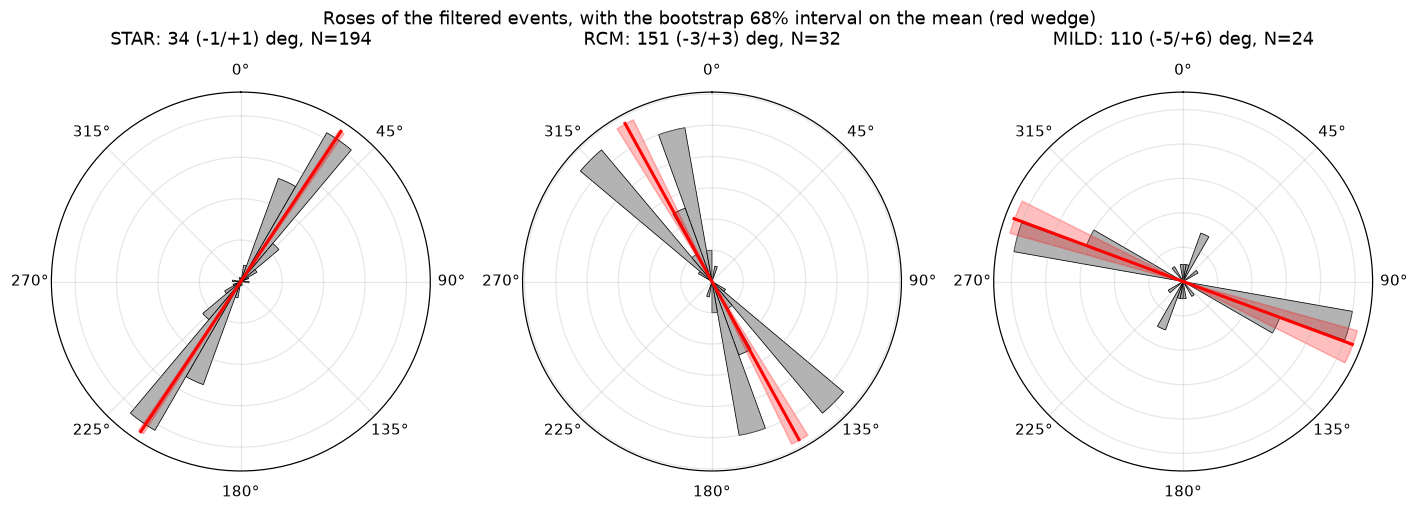

In [5]:
fig = plt.figure(figsize=(13, 4.5))
for i, s in enumerate(STATIONS):
    kept = quality.post_filtered(res[s]); r = summary.loc[s]
    ax = fig.add_subplot(1, 3, i + 1, projection="polar"); ax.set_theta_zero_location("N"); ax.set_theta_direction(-1)
    phi = measure.phi_0_180(kept.phi); bins = np.arange(0, 181, 10); c, _ = np.histogram(phi, bins)
    th = np.deg2rad(np.concatenate([bins[:-1], bins[:-1] + 180]))
    ax.bar(th, np.concatenate([c, c]), width=np.deg2rad(10), color="0.7", edgecolor="k", lw=0.5, align="edge")
    rmax = ax.get_ylim()[1]
    for base in (0, 180):
        ax.plot([np.deg2rad(r.mean_phi + base)] * 2, [0, rmax], "r-", lw=2)
        wedge = np.deg2rad(np.linspace(r.mean_phi + r["phi_-"] + base, r.mean_phi + r["phi_+"] + base, 20))
        ax.fill_between(wedge, 0, rmax, color="r", alpha=0.25)
    ax.set_yticklabels([]); ax.set_title(f"{s}: {r.mean_phi:.0f} ({r['phi_-']:+.0f}/{r['phi_+']:+.0f}) deg, N={int(r.N)}", pad=12)
fig.suptitle("Roses of the filtered events, with the bootstrap 68% interval on the mean (red wedge)"); plt.tight_layout()

## 3. Post-processing thresholds: sweep the post-processing cuts

Each post-processing cut is a parameter in `quality.PostFilter`. Sweep one at a time and track N, mean phi and mean dt. A result that is stable across reasonable values is robust; one that jumps is telling you the threshold is doing the work.

In [6]:
def summarize(r, g):
    kept = quality.post_filtered(r, g)
    if len(kept) < 5: return {"N": len(kept), "mean_phi": np.nan, "R": np.nan, "mean_dt": np.nan}
    m, R = stats.axial_mean(kept.phi)
    return {"N": len(kept), "mean_phi": m, "R": R, "mean_dt": kept.dt.mean()}

sweeps = {
    "qw_min": [0.3, 0.4, 0.5, 0.6, 0.75, 0.9],
    "snr_min": [1.5, 2.0, 2.5, 3.0, 4.0, 6.0],
    "phi_error_max": [5, 10, 15, 20, 30, 45],
    "dt_error_max": [0.01, 0.02, 0.03, 0.05, 0.08, 0.12],
}
rows = []
for s in STATIONS:
    for param, values in sweeps.items():
        for v in values:
            g = quality.PostFilter(**{param: v})
            rows.append({"station": s, "param": param, "value": v, **summarize(res[s], g)})
sweep = pd.DataFrame(rows)
sweep[(sweep.station == "STAR") & (sweep.param == "qw_min")]

,station,param,value,N,mean_phi,R,mean_dt
0,STAR,qw_min,0.30,211,34.743885,0.827386,0.051564
1,STAR,qw_min,0.40,211,34.743885,0.827386,0.051564
2,STAR,qw_min,0.50,206,34.529056,0.836615,0.051456
3,STAR,qw_min,0.60,204,34.294971,0.844731,0.051765
4,STAR,qw_min,0.75,194,33.699958,0.862517,0.052268
5,STAR,qw_min,0.90,175,33.032098,0.869813,0.053714


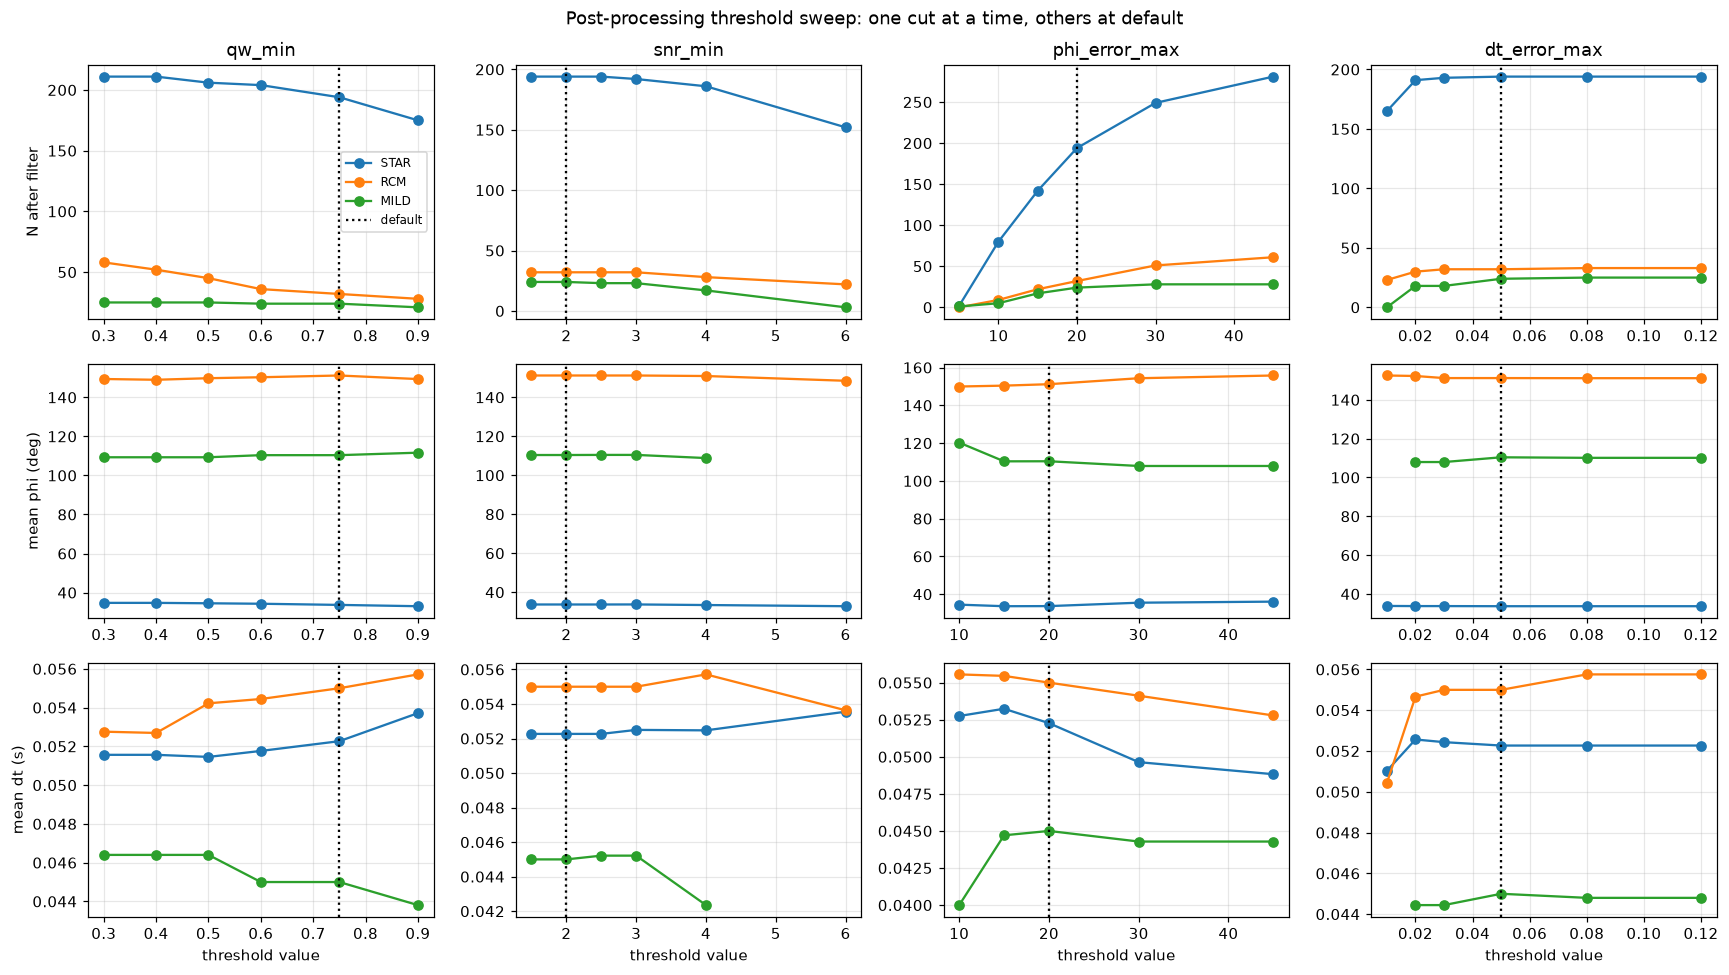

In [7]:
fig, axes = plt.subplots(3, 4, figsize=(16, 9))
for j, (param, values) in enumerate(sweeps.items()):
    for i, (metric, lab) in enumerate([("N", "N after filter"), ("mean_phi", "mean phi (deg)"), ("mean_dt", "mean dt (s)")]):
        ax = axes[i, j]
        for s in STATIONS:
            d = sweep[(sweep.station == s) & (sweep.param == param)]
            ax.plot(d.value, d[metric], "o-", label=s)
        default = getattr(quality.DEFAULT_POST, param)
        ax.axvline(default, color="k", ls=":", label="default" if (i == 0 and j == 0) else None)
        if i == 0: ax.set_title(param)
        if i == 2: ax.set_xlabel("threshold value")
        if j == 0: ax.set_ylabel(lab)
axes[0, 0].legend(fontsize=8); fig.suptitle("Post-processing threshold sweep: one cut at a time, others at default"); plt.tight_layout()

What to look for: N changes a lot (the cuts are doing their job), but does **mean phi** move by more than its bootstrap interval? For STAR the mean stays between 33 and 36 degrees across every sweep, which sounds robust, and largely is: Q_w ≥ 0.9, which drops 19 of the 194 events, moves it by less than a degree, and the largest move (to 36 degrees) comes from loosening `phi_error_max` to 45 degrees, which lets in 87 more events. But section 7 shows that the swings with `qw_min` and `phi_error_max` (1.0 and 2.4 degrees) are as large as or larger than STAR's bootstrap interval of about ±1 degree. With 194 events the sample is precise enough that the threshold, not the sample, sets the last degree or two. If a station's mean phi swings with Q_w or phi_error_max, the pooled direction is being decided by the filter, and the honest statement is "undetermined with this sample".

## 4. Pre-processing gates: the incidence cutoff

The pre-gates decide which events are *attempted*. The incidence gate removed almost everything at five stations. We cannot re-measure rejected events here (that needs the full re-run), but we can ask two cheaper questions with the stored angles: how many events each cutoff would admit, and for the events that were measured, does the mean phi depend on how steeply they arrived?

In [8]:
ALL = ["STAR", "RCM", "MILD", "LON", "PANH", "OBSR", "PARA", "RER", "COPP"]
allres = {s: pd.read_csv(paths.station_results_csv(s, oriented=(s == "STAR"))) for s in ALL}
cutoffs = [30, 35, 40, 45, 50, 55, 60, 70]
admit = pd.DataFrame({s: [int((r.incidence_angle <= c).sum()) for c in cutoffs] for s, r in allres.items()}, index=cutoffs)
admit.index.name = "incidence cutoff (deg)"
admit

,STAR,RCM,MILD,LON,PANH,OBSR,PARA,RER,COPP
incidence cutoff (deg),,,,,,,,,
30,549,17,1,0,0,0,0,0,0
35,726,93,2,0,0,0,0,0,0
40,825,225,23,0,0,0,0,0,0
45,848,339,134,0,0,2,1,0,0
50,862,424,305,0,0,7,1,0,0
55,872,461,476,0,1,25,2,1,3
60,880,478,581,0,8,52,9,31,13
70,898,487,656,549,268,114,465,322,258


Text(0.5, 1.0, 'How many events each station would attempt versus the incidence cutoff')

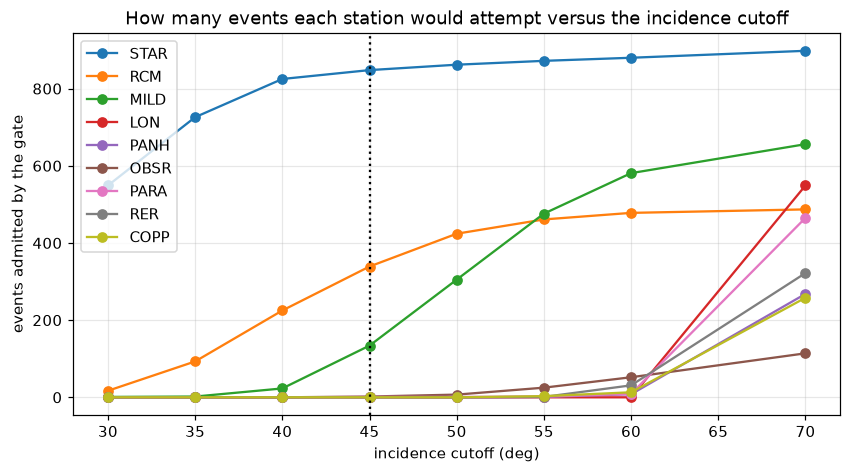

In [9]:
ax = admit.plot(figsize=(9, 4.5), marker="o"); ax.axvline(45, color="k", ls=":")
ax.set_ylabel("events admitted by the gate"); ax.set_title("How many events each station would attempt versus the incidence cutoff")

For PANH, PARA, RER and COPP the curve stays at zero until far past 45 degrees: the geometry really is outside the shear-wave window under this velocity model. OBSR and MILD are borderline. LON looks like the worst case in the table (nothing until 70 degrees), but it is the exception: the pipeline gated LON on the data-derived Jurkevics angle, not on these stored ray-traced angles, which is why LON has measurements at all (notebook 06, exercise 2). Relaxing the cutoff is *not* a free lunch: beyond about 45 degrees the free-surface reflection distorts S-wave particle motion and the measurement loses its meaning (Crampin & Peacock, 2008). The right benchmark is therefore not "how many events can we admit" but "at what angle do the measurements become unreliable", which is a synthetic or a near-station versus far-station comparison. Write that down as a project idea.

In [10]:
# Among measured STAR events, does phi depend on incidence angle? (bins of ray-traced angle)
kept = quality.post_filtered(allres["STAR"]).copy()
kept["inc_bin"] = pd.cut(kept.incidence_angle, [0, 20, 30, 40, 45])
tab = kept.groupby("inc_bin", observed=True).agg(N=("phi", "size"), mean_phi=("phi", lambda p: stats.axial_mean(p)[0]),
                                               R=("phi", lambda p: stats.axial_mean(p)[1]), mean_dt=("dt", "mean")).round(2)
tab

,N,mean_phi,R,mean_dt
inc_bin,,,,
"(0, 20]",34,33.84,0.91,0.06
"(20, 30]",122,33.44,0.86,0.06
"(30, 40]",36,35.39,0.83,0.04
"(40, 45]",2,19.30,1.00,0.04


Among STAR's filtered events, the mean fast direction does not depend on how steeply the ray arrives: 34, 33 and 35 degrees for rays 0 to 20, 20 to 30 and 30 to 40 degrees from vertical (N = 34, 122 and 36), with R between 0.83 and 0.91. The 40 to 45 bin has two events, so ignore it. (The pre-fix results drifted from 98 to 81 degrees across the same bins; that drift came from the exchanged channels.) What does change is dt, whose mean falls from 0.06 to 0.04 s as the rays get shallower. Before reading physics into that, check the filter bands: most 1-5 Hz events have dt 0.06 s and most 5-10 Hz events 0.02 s (notebook 03), and about half of the 30-40 degree bin chose 5-10 Hz, against under a tenth of the steeper bins. Within the 1-5 Hz band alone, dt is the same in every bin (0.059 to 0.062 s). So the trend is mostly a change in the band mix, not path length or different rock.

## 5. Null screening

Flag filtered events whose fast axis is within 20 degrees of the back azimuth or of its perpendicular. Report the pooled mean with and without them. If the answer changes, the pooled direction may be partly an artifact of initial polarization.

In [11]:
rows = []
for s in STATIONS:
    kept = quality.post_filtered(res[s]).copy()
    d = stats.axial_diff(kept.phi, kept.back_azimuth)
    kept["near_null"] = (d <= 20) | (d >= 70)
    non_null = kept[~kept.near_null]
    m_all, R_all = stats.axial_mean(kept.phi); m_keep, R_keep = stats.axial_mean(non_null.phi) if len(non_null) >= 5 else (np.nan, np.nan)
    rows.append({"station": s, "N": len(kept), "N_near_null": int(kept.near_null.sum()), "frac_near_null": round(kept.near_null.mean(), 2),
                 "mean_phi_all": round(m_all, 1), "mean_phi_without": round(m_keep, 1), "R_all": round(R_all, 2), "R_without": round(R_keep, 2)})
pd.DataFrame(rows).set_index("station")

,N,N_near_null,frac_near_null,mean_phi_all,mean_phi_without,R_all,R_without
station,,,,,,,
STAR,194,57,0.29,33.7,35.5,0.86,0.95
RCM,32,15,0.47,151.2,163.2,0.85,0.94
MILD,24,22,0.92,110.4,NaN,0.42,NaN


At STAR 29 percent of the filtered measurements are near-null by this definition (two-sided: within 20 degrees of the back azimuth *or* of its perpendicular). That is below the 44 percent that fast directions scattered at random would give (exercise 3), and removing them barely moves the mean (33.7 to 35.5 degrees) while tightening the rose (R 0.86 to 0.95). Nearly all rays still arrive from the east, though, so the dataset cannot by itself rule out a polarization effect, and that argues for exactly what the project plans next: more stations, better geometry, and the nodal array.

Before the channel fix this was the single most important caveat on the preliminary results: 93 percent of STAR's pre-fix filtered set was near-null, because the fast axis came out east-west, parallel to the rays. MILD still looks like that (92 percent near-null, too few left to average without them), so MILD is now the station where this caveat bites.

## 6. Processing sensitivity on one event

Finally, the knobs inside a single measurement. Re-measure the figure-3 event with the S pick shifted, with more or fewer windows, and with wider time-shift and pick-uncertainty limits. Each run takes well under a second (the first takes a few seconds while numba compiles the grid search).

In [12]:
cat = data.load_station_catalog("STAR")
row = cat[cat.evid == 61504668].iloc[0]
ev = data.get_event_stream("STAR", row, allow_download=False)
lat, lon, _ = data.station_coords("STAR")
inc = float(res["STAR"].set_index("evid").loc[61504668, "incidence_angle"])

def run(label, row=row, params=measure.SwsParams()):
    m = measure.measure_event(row, ev, "STAR", lat, lon, incidence_angle=inc, params=params)
    return {"case": label, "stage": m.stage, "phi": m.phi, "dt": m.dt, "phi_err": m.phi_error, "dt_err": m.dt_error, "Q_w": m.quality}

cases = [run("baseline")]
for shift in (-0.03, +0.03):
    r2 = row.copy(); r2["s_time"] = row.s_time + pd.Timedelta(seconds=shift)
    cases.append(run(f"S pick {shift:+.2f} s", row=r2))
cases.append(run("n_win = 3", params=measure.SwsParams(n_win=3)))
cases.append(run("n_win = 11", params=measure.SwsParams(n_win=11)))
cases.append(run("max_t_shift = 0.1 s", params=measure.SwsParams(max_t_shift_s=0.1)))
cases.append(run("s_pick_uncertainty = 0.06", params=measure.SwsParams(s_pick_uncertainty=0.06)))
pd.DataFrame(cases).set_index("case").round(3)

,stage,phi,dt,phi_err,dt_err,Q_w
case,,,,,,
baseline,ok,-84.783,0.02,11.0,0.01,-0.272
S pick -0.03 s,ok,37.217,0.02,12.0,0.01,1.000
S pick +0.03 s,ok,35.217,0.02,10.0,0.01,0.497
n_win = 3,fail_no_result,NaN,NaN,NaN,NaN,NaN
n_win = 11,ok,-84.783,0.02,11.0,0.01,-0.272
max_t_shift = 0.1 s,ok,35.217,0.02,14.0,0.01,0.969
s_pick_uncertainty = 0.06,ok,35.217,0.02,11.0,0.01,0.969


Read this table carefully; it is more interesting than it looks. (This is the corrected figure-3 event from notebook 05, section 4.)

- **dt does not move**: 0.02 s in every case that gives an answer.
- **phi has two answers.** The baseline, and `n_win = 11`, give 95 degrees (east-west, 6 degrees from the back azimuth) with Q_w -0.27, which in the Wüstefeld scheme leans towards a null. Shifting the S pick 0.03 s either way, allowing a 0.1 s time shift or widening `s_pick_uncertainty` gives 35 to 37 degrees instead (north-north-east, the direction most corrected STAR events give), with Q_w from 0.50 to 1.0 (all but the 0.50 above the 0.75 cut). Whether this event ends up in the final rose, and with which fast direction, depends on a three-sample pick shift or a window parameter, not on the data. The quality score is the only thing standing between a measurement and the rose, and here it is as fragile as the measurement.
- `n_win = 3` fails outright: SWSPy tries `n_win` × `n_win` windows (every combination of a start and an end), 9 here, and the clustering step needs at least `cluster_min_samples` (15) agreeing results. A parameter can be *incompatible* with another, not just worse.

This is the whole argument for benchmarking thresholds alongside measurements: one event's place in the result can hinge on a knob nobody thinks about. The sweep in section 3 tells you how often that happens across a station.

Repeat this for a *marginal* event (Q_w near 0.75, SNR near 2) and watch more of the rows fall apart.

## 7. Turning this into a benchmark

Everything above is a one-off. The deliverable for the project is a function that takes a station's results and a set of thresholds and returns the summary table of section 2 plus the sensitivity of section 3, so that *every* station and every future re-run is judged the same way. A sketch:

In [13]:
def benchmark(results: pd.DataFrame, filt: quality.PostFilter = quality.DEFAULT_POST, n_boot=500) -> dict:
    """Pooled estimate with uncertainty, plus its sensitivity to each post-processing threshold."""
    kept = quality.post_filtered(results, filt)
    m, lo, hi, _ = stats.bootstrap_axial_mean(kept.phi, n_boot=n_boot)
    out = {"N": len(kept), "mean_phi": m, "phi_ci": (lo, hi), "mean_dt": kept.dt.mean(),
           "dt_ci": stats.bootstrap(kept.dt.values, np.mean, n_boot=n_boot)[1:3]}
    for param, values in sweeps.items():
        phis = [summarize(results, quality.PostFilter(**{param: v}))["mean_phi"] for v in values]
        out[f"phi_range_vs_{param}"] = float(np.nanmax(stats.axial_diff(phis, m)))   # worst-case swing of mean phi
    return {k: (tuple(round(x, 3) for x in v) if isinstance(v, tuple) else (round(v, 3) if isinstance(v, float) else v)) for k, v in out.items()}

pd.DataFrame({s: benchmark(res[s]) for s in STATIONS}).T

,N,mean_phi,phi_ci,mean_dt,dt_ci,phi_range_vs_qw_min,phi_range_vs_snr_min,phi_range_vs_phi_error_max,phi_range_vs_dt_error_max
STAR,194,33.7,"(-0.874, 1.028)",0.052,"(0.051, 0.054)",1.044,0.883,2.365,0.138
RCM,32,151.182,"(-2.976, 2.482)",0.055,"(0.052, 0.058)",2.19,2.71,4.608,1.328
MILD,24,110.385,"(-4.682, 6.142)",0.045,"(0.043, 0.048)",1.269,1.557,9.883,2.442


`phi_range_vs_<param>` is the largest swing of the mean fast direction as that threshold moves across its sweep. If it is smaller than the bootstrap interval, the result is threshold-robust. That single comparison is the standard you will apply as you scale to more stations.

## 8. Exercises and project ideas

1. Run `benchmark` for LON and for the VT background at STAR (`results/sws_vt_star_results.csv`). Is the background fast direction the same as the swarm's?
2. Repeat section 6 for a marginal event. Which knob breaks it first?
3. Change the near-null definition to 10 and 30 degrees. How sensitive is the fraction?
4. **Calibration project:** generate synthetic split events by taking a clean STAR S wave, undoing its splitting with `swspy.splitting.split_windowcheck.remove_splitting`, re-splitting with known (phi, dt), adding real pre-event noise at chosen SNR, and pushing the result through `measure_event`. Compare recovered errors with the reported ones. This is the real version of notebook 04, section 5.
5. **Incidence-gate project:** using the synthetic events above with the LQT rotation at several nominal incidence angles, find the angle at which recovery degrades. Compare with the 45-degree gate.

When you can run `benchmark` on every station from one script and explain each number in it, you are done with this tutorial series and ready for the real analysis.

That script is the week-8 deliverable. What comes after it, in priority order, is the *Winter quarter* section of the README: the timing correction from notebook 04b applied to the pipeline, the 2009 swarm at STAR, all of 2025 at STAR, and a first look at the nodes.

## 9. Example solutions

One way to do each exercise. Try them yourself first. Exercises 1 and 3 use the stored results: STAR's corrected re-run, except that exercise 1 compares the VT background with the pre-fix swarm (note at the top). Exercises 2, 4 and 5 re-measure orientation-corrected waveforms. Items 4 and 5 are projects of several weeks; what is here is a working *starting point*, small enough to run in a minute or two.

### Exercise 1: LON and the VT background at STAR

`benchmark` works on any results table. The VT background file holds STAR measurements of ordinary volcano-tectonic earthquakes from before the swarm, so comparing it with the swarm asks whether the swarm changed the fast direction. To say whether two pooled directions differ, compare the gap between them with what you would get by chance: shuffle the swarm/background labels many times and see how often the shuffled gap is as large as the real one (a permutation test).

In [14]:
# The VT background has not been re-run on corrected channels, so compare it with the swarm as
# measured the same way (pre-fix); the corrected swarm is in the table for reference.
vt = pd.read_csv(paths.RESULTS / "sws_vt_star_results.csv")
star_prefix = pd.read_csv(paths.station_results_csv("STAR"))
when = pd.to_datetime(vt.datetime, format="ISO8601")
print(f"VT background at STAR: {len(vt)} events, {when.min():%Y-%m-%d} to {when.max():%Y-%m-%d}, "
      f"{len(quality.post_filtered(vt))} pass the filter")

bench = pd.DataFrame({"STAR swarm, corrected": benchmark(res["STAR"]), "STAR swarm, pre-fix": benchmark(star_prefix),
                      "STAR VT background, pre-fix": benchmark(vt),
                      "LON swarm": benchmark(allres["LON"])}).T
bench

VT background at STAR: 138 events, 2015-02-02 to 2025-06-27, 20 pass the filter


,N,mean_phi,phi_ci,mean_dt,dt_ci,phi_range_vs_qw_min,phi_range_vs_snr_min,phi_range_vs_phi_error_max,phi_range_vs_dt_error_max
"STAR swarm, corrected",194,33.7,"(-0.874, 1.028)",0.052,"(0.051, 0.054)",1.044,0.883,2.365,0.138
"STAR swarm, pre-fix",110,91.365,"(-1.797, 1.587)",0.039,"(0.036, 0.041)",1.536,3.409,3.698,1.36
"STAR VT background, pre-fix",20,83.786,"(-4.735, 3.931)",0.023,"(0.021, 0.025)",2.137,9.617,5.963,0.0
LON swarm,38,7.431,"(-3.27, 3.074)",0.025,"(0.023, 0.028)",0.807,4.014,5.97,2.621


In [15]:
def permutation_gap(phi_a, phi_b, n=2000, seed=0):
    """Axial gap between two mean directions, and how often label shuffling gives a gap at least as large."""
    phi_a, phi_b = np.asarray(phi_a), np.asarray(phi_b)
    gap = stats.axial_diff(stats.axial_mean(phi_a)[0], stats.axial_mean(phi_b)[0])
    pooled, rng, count = np.concatenate([phi_a, phi_b]), np.random.default_rng(seed), 0
    for _ in range(n):
        rng.shuffle(pooled)
        count += stats.axial_diff(stats.axial_mean(pooled[:len(phi_a)])[0], stats.axial_mean(pooled[len(phi_a):])[0]) >= gap
    return gap, count / n

swarm, background = quality.post_filtered(star_prefix).phi, quality.post_filtered(vt).phi   # both pre-fix
gap, p = permutation_gap(swarm, background)
print(f"STAR swarm vs VT background (both pre-fix): mean directions differ by {gap:.1f} deg, permutation p = {p:.3f}")
print(f"(R: swarm {stats.axial_mean(swarm)[1]:.2f}, background {stats.axial_mean(background)[1]:.2f}; "
      f"Rayleigh p for the background {stats.rayleigh_test(background)[1]:.3f})")

STAR swarm vs VT background (both pre-fix): mean directions differ by 7.6 deg, permutation p = 0.147
(R: swarm 0.46, background 0.70; Rayleigh p for the background 0.000)


**VT background versus swarm at STAR.** The background (20 filtered events, 2015 to June 2025) has a mean fast direction of about 84 degrees against the pre-fix swarm's 91, a gap of 7.6 degrees. Shuffling the labels gives a gap at least that large 15 percent of the time (p = 0.15), so with these samples **there is no detectable change** in direction. The background is more tightly clustered (R 0.70 against 0.46) and has smaller delays (mean dt 0.023 s against 0.039), which may be more interesting than the direction, but its N is small and its mean moves by about 10 degrees as `snr_min` is swept, about twice its bootstrap interval. Both sets come from STAR's channels *as labelled* (the exchange applies to the whole 2014-onward installation), so this is a like-for-like comparison of two numbers that are wrong in the same way. The corrected swarm (first row of the table) points about 34 degrees, with delays twice the background's; whether the background agrees needs it re-run on corrected channels, and its waveforms are not in this repo.

**LON.** 38 filtered events with a mean fast direction of about 7 degrees (68 percent interval about ±3), close to north-south and about 26 degrees from STAR's corrected 34. Its threshold swings reach 4 to 6 degrees (with `snr_min` and `phi_error_max`), somewhat larger than its ±3-degree bootstrap interval, so the last few degrees of LON's direction are set by the thresholds. Remember that LON was gated on the Jurkevics incidence angle, not the ray-traced one used everywhere else, so its event selection follows a different rule from the other stations'.

### Exercise 2: a marginal event

Event 61504373 is marginal on the corrected data: it passes every post-processing cut, but only just, with SNR 2.5 (the cut is 2) and phi_error exactly 20 degrees (the cut is 20). (An earlier version of this exercise used 62135967, whose S wave turns out to have clipped; the research re-run rejects it as `fail_clipped`. `measure_event` has no clipping check, so it measured that event without complaint.) Turn the same knobs as section 6, with the pick moved in smaller steps so you can see which knob breaks it *first*. The section-6 `run` helper is tied to the figure-3 event, so here is the same thing with the event as an argument.

In [16]:
MARGINAL = 61504373
row_m = cat[cat.evid == MARGINAL].iloc[0]
ev_m = data.get_event_stream("STAR", row_m, allow_download=False)
inc_m = float(res["STAR"].set_index("evid").loc[MARGINAL, "incidence_angle"])

def run_event(label, ev_, row_, inc_, params=measure.SwsParams()):
    m = measure.measure_event(row_, ev_, "STAR", lat, lon, incidence_angle=inc_, params=params)
    passes = bool(quality.post_filter_mask(pd.DataFrame([m.as_row()])).iloc[0]) if m.stage == "ok" else False
    return {"case": label, "stage": m.stage, "phi": m.phi, "dt": m.dt, "phi_err": m.phi_error,
            "dt_err": m.dt_error, "Q_w": m.quality, "SNR": m.snr_horizontal, "passes filter": passes}

cases = [run_event("baseline", ev_m, row_m, inc_m)]
for shift in (-0.03, -0.02, -0.01, +0.01, +0.02, +0.03):
    r2 = row_m.copy(); r2["s_time"] = row_m.s_time + pd.Timedelta(seconds=shift)
    cases.append(run_event(f"S pick {shift:+.2f} s", ev_m, r2, inc_m))
for n_win in (5, 9, 11):
    cases.append(run_event(f"n_win = {n_win}", ev_m, row_m, inc_m, params=measure.SwsParams(n_win=n_win)))
cases.append(run_event("max_t_shift = 0.1 s", ev_m, row_m, inc_m, params=measure.SwsParams(max_t_shift_s=0.1)))
cases.append(run_event("s_pick_uncertainty = 0.06", ev_m, row_m, inc_m, params=measure.SwsParams(s_pick_uncertainty=0.06)))
print("default n_win:", measure.SwsParams().n_win)
pd.DataFrame(cases).set_index("case").round(3)

default n_win: 7


,stage,phi,dt,phi_err,dt_err,Q_w,SNR,passes filter
case,,,,,,,,
baseline,ok,11.53,0.04,20.0,0.01,0.937,2.510,True
S pick -0.03 s,ok,11.53,0.04,18.0,0.01,0.000,2.287,False
S pick -0.02 s,ok,1.53,0.04,21.0,0.01,0.195,2.291,False
S pick -0.01 s,ok,9.53,0.04,20.0,0.01,0.969,2.329,True
S pick +0.01 s,ok,43.53,0.02,11.0,0.01,0.114,2.657,False
S pick +0.02 s,ok,43.53,0.02,9.0,0.01,0.094,2.601,False
S pick +0.03 s,ok,43.53,0.02,9.0,0.01,0.094,2.477,False
n_win = 5,ok,5.53,0.04,24.0,0.01,0.969,2.510,False
n_win = 9,ok,43.53,0.02,11.0,0.01,0.094,2.510,False


**Which knob breaks it first?** The pick. Of the twelve runs only four pass the post-processing filter: the baseline, the pick 0.01 s earlier, 11 windows and a wider `s_pick_uncertainty`. Two kinds of breaking show up:

- **A different answer.** Moving the S pick 0.01 to 0.03 s *later*, or using 9 windows, gives phi 44 degrees and dt 0.02 s instead of 12 degrees and 0.04 s: a jump of 32 degrees, with a *smaller* reported phi error (9 to 11 degrees) than the baseline's 20. Q_w catches it (0.09 to 0.11), so none of those passes.
- **The same answer, rejected.** Moving the pick 0.02 or 0.03 s earlier keeps phi within 10 degrees (2 and 12) and dt at 0.04 s, but Q_w drops to 0.20 and 0. With 5 windows (phi 6) or a 0.1 s maximum time shift (phi 12) the answer barely moves, but phi_error goes over 20 degrees (24 and 31). The event leaves the filtered set although its fast direction hardly changed.

So a pick shift of one sample (0.01 s) decides whether this event is in the rose, and with which fast direction. The figure-3 event of section 6 goes the other way (its baseline fails, its shifted picks pass); both directions happen, which is the case for a perturbation test in the benchmark: sweep the pick within its uncertainty and keep only events whose phi and membership are stable. Note also that the SNR column changes with the pick (2.29 to 2.66), because the SNR windows are placed relative to the S pick, and that `n_win = 5` does give an answer here: whether the clustering step succeeds depends on how many of the 25 windows agree, not only on how many there are.

### Exercise 3: how sensitive is the near-null fraction?

Section 5 calls a measurement near-null when the fast axis is within 20 degrees of the back azimuth *or of its perpendicular*. Note what that band covers: 2 × 20 = 40 of the 90 possible degrees of separation, so even fast directions scattered at random would be "near-null" 44 percent of the time. Compare each fraction with that chance level.

In [17]:
rows = []
for s in STATIONS:
    kept = quality.post_filtered(res[s])
    d = stats.axial_diff(kept.phi, kept.back_azimuth)
    for width in (10, 20, 30):
        frac = float(((d <= width) | (d >= 90 - width)).mean())
        rows.append({"station": s, "N": len(kept), "width (deg)": width, "fraction near-null": round(frac, 2),
                     "chance level": round(2 * width / 90, 2), "excess over chance": round(frac - 2 * width / 90, 2)})
pd.DataFrame(rows).set_index(["station", "width (deg)"])

N  fraction near-null  chance level  excess over chance
station width (deg)                                                           
STAR    10           194                0.10          0.22               -0.12
        20           194                0.29          0.44               -0.15
        30           194                0.56          0.67               -0.11
RCM     10            32                0.34          0.22                0.12
        20            32                0.47          0.44                0.02
        30            32                0.62          0.67               -0.04
MILD    10            24                0.50          0.22                0.28
        20            24                0.92          0.44                0.47
        30            24                0.92          0.67                0.25

**The raw fraction is very sensitive to the width; the excess over chance is the number to report.** A wider band catches more directions by chance (22, 44 and 67 percent at 10, 20 and 30 degrees). STAR's fractions (10, 29 and 56 percent) are *below* chance at every width, by 0.11 to 0.15: its fast directions sit away from the null directions (the mean, 34 degrees, is about 58 degrees from the back azimuth of about 92). Before the channel fix STAR was 74 to 96 percent near-null, about 0.5 above chance. RCM's fractions are **close to chance** at every width (excess between -0.04 and +0.12), so RCM's fast directions show no special relation to its back azimuths. MILD is the station to worry about: 50 to 92 percent near-null, 0.25 to 0.47 above chance, with only 24 events.

When you report a near-null fraction, give the width, the chance level and N.

### Exercise 4 (project): calibrating the reported errors with synthetic events

A **starting point**. The recipe:

1. Take a clean corrected STAR event (62138582: SNR about 12, Q_w 0.97) and measure it.
2. Undo its splitting with `remove_splitting`, which works in the ray (Q-T) frame: its phi is `phi_from_Q`, which is `phi_from_N` minus the back azimuth.
3. Split it again with a phi and dt that *we* choose. Running `remove_splitting` with a negative dt applies the splitting instead of removing it, through exactly the same rotations the measurement uses.
4. Add real noise: the 5 s before the origin of four other cached STAR events, spliced together, scaled to a chosen SNR (RMS of the horizontals in the first 0.5 s after S, over the RMS of the noise; not the pipeline's SNR, which compares S with the P coda, notebook 03).
5. Measure, and compare the actual error with the reported one.

In [18]:
from swspy.splitting.split_windowcheck import remove_splitting

CLEAN = 62138582
row_c = cat[cat.evid == CLEAN].iloc[0]
ev_c = data.get_event_stream("STAR", row_c, allow_download=False)
inc_c = float(res["STAR"].set_index("evid").loc[CLEAN, "incidence_angle"])
m_c = measure.measure_event(row_c, ev_c, "STAR", lat, lon, incidence_angle=inc_c)
r_c = m_c.splitting_object.sws_result_df.iloc[0]
baz_c, src_pol = m_c.back_azimuth, r_c.src_pol_from_N
print(f"clean event: phi {r_c.phi_from_N:.1f} deg from N ({r_c.phi_from_Q:.1f} from Q), dt {r_c['dt']:.2f} s, "
      f"Q_w {r_c.Q_w:.2f}, source polarization {src_pol:.1f} deg, back azimuth {baz_c:.1f}, incidence {inc_c:.1f}")

base = ev_c.copy()
for tr in base:
    tr.data = tr.data.astype(float) - tr.data.mean()
unsplit = remove_splitting(base, r_c.phi_from_Q, r_c["dt"], baz_c, inc_c, return_FS=False)
m_u = measure.measure_event(row_c, unsplit, "STAR", lat, lon, incidence_angle=inc_c)
print(f"after removing it: phi {m_u.phi:.1f}, dt {m_u.dt:.2f} s, Q_w {m_u.quality:.2f}")

def split(st, phi_N, dt, inc=inc_c):
    """Apply splitting with fast direction phi_N (deg from N) and delay dt, in the measurement's own frame."""
    return remove_splitting(st, phi_N - baz_c, -dt, baz_c, inc, return_FS=False)

s_c = data.to_utc(row_c.s_time)
def horizontal_rms(st, t0=None, t1=None):
    return np.sqrt(np.mean(np.concatenate([(tr.slice(t0, t1) if t0 else tr).data ** 2 for tr in st.select(channel="??[NE]")])))
signal_rms = horizontal_rms(unsplit, s_c, s_c + 0.5)

cached = data.describe_cache("STAR").query("complete").evid
donors = cat[cat.evid.isin(cached) & (cat.evid != CLEAN)]
def real_noise(seed):
    """20 s of three-component noise: the 5 s before origin of four other events, spliced, unit horizontal RMS."""
    comps = {c: [] for c in "ZNE"}
    for _, r in donors.sample(4, random_state=seed).iterrows():
        for tr in data.get_event_stream("STAR", r, allow_download=False):
            seg = tr.data[:500].astype(float)
            comps[tr.stats.channel[-1]].append(seg - seg.mean())
    out = unsplit.copy()
    for tr in out:
        tr.data = np.concatenate(comps[tr.stats.channel[-1]])[:tr.stats.npts]
    scale = horizontal_rms(out)
    for tr in out:
        tr.data /= scale
    return out

def synthetic(phi_N, dt, snr, seed, inc=inc_c):
    st, noise = split(unsplit, phi_N, dt, inc), real_noise(seed)
    for tr in st:
        tr.data = tr.data + noise.select(channel="??" + tr.stats.channel[-1])[0].data * signal_rms / snr
    return st

clean event: phi 22.8 deg from N (-68.0 from Q), dt 0.02 s, Q_w 0.97, source polarization 6.9 deg, back azimuth 90.8, incidence 34.2


after removing it: phi 0.8, dt 0.04 s, Q_w 0.00


In [19]:
import time
t0, rows = time.time(), []
for offset in (45, 20):                                   # fast axis this far from the source polarization
    phi_true = (src_pol + offset) % 180
    for dt_true in (0.04, 0.08):
        for snr in (10, 3):
            for seed in range(4):
                m = measure.measure_event(row_c, synthetic(phi_true, dt_true, snr, seed), "STAR", lat, lon, incidence_angle=inc_c)
                r = m.as_row()
                ok_ = m.stage == "ok"
                rows.append({"offset from src pol": offset, "phi_true": round(phi_true, 1), "dt_true": dt_true, "SNR": snr,
                             "seed": seed, "stage": m.stage,
                             "phi_err_actual": stats.axial_diff(m.phi, phi_true) if ok_ else np.nan,
                             "phi_err_reported": m.phi_error if ok_ else np.nan,
                             "dt_err_actual": abs(m.dt - dt_true) if ok_ else np.nan,
                             "dt_err_reported": m.dt_error if ok_ else np.nan, "Q_w": m.quality,
                             "passes filter": bool(quality.post_filter_mask(pd.DataFrame([r])).iloc[0]) if ok_ else False})
calib = pd.DataFrame(rows)
print(f"{len(calib)} synthetic measurements in {time.time() - t0:.0f} s")

def within(a, b): return (a <= np.maximum(b, 1e-9)).mean()
summary_c = calib.groupby(["offset from src pol", "dt_true", "SNR"]).apply(lambda g: pd.Series({
    "measured": (g.stage == "ok").sum(), "passes filter": g["passes filter"].sum(),
    "median phi err actual": g.phi_err_actual.median(), "median phi err reported": g.phi_err_reported.median(),
    "phi actual <= reported": within(g.phi_err_actual.dropna(), g.phi_err_reported.dropna()),
    "median dt err actual": g.dt_err_actual.median(), "median dt err reported": g.dt_err_reported.median()}),
    include_groups=False).round(2)
summary_c

32 synthetic measurements in 7 s


measured  passes filter  \
offset from src pol dt_true SNR                            
20                  0.04    3         3.0            2.0   
                            10        4.0            3.0   
                    0.08    3         3.0            0.0   
                            10        4.0            0.0   
45                  0.04    3         3.0            1.0   
                            10        2.0            2.0   
                    0.08    3         4.0            0.0   
                            10        4.0            0.0   

                                 median phi err actual  \
offset from src pol dt_true SNR                          
20                  0.04    3                     6.07   
                            10                    2.07   
                    0.08    3                     2.07   
                            10                    4.07   
45                  0.04    3                    12.93   
                            10                    1.00   
                    0.08    3                     4.07   
                            10                    5.07   

                                 median phi err reported  \
offset from src pol dt_true SNR                            
20                  0.04    3                       14.0   
                            10                      13.5   
                    0.08    3                        6.0   
                            10                       8.0   
45                  0.04    3                       21.0   
                            10                      10.5   
                    0.08    3                       15.0   
                            10                       9.0   

                                 phi actual <= reported  median dt err actual  \
offset from src pol dt_true SNR                                                 
20                  0.04    3                      1.00                   0.0   
                            10                     1.00                   0.0   
                    0.08    3                      0.67                   0.0   
                            10                     1.00                   0.0   
45                  0.04    3                      1.00                   0.0   
                            10                     1.00                   0.0   
                    0.08    3                      1.00                   0.0   
                            10                     1.00                   0.0   

                                 median dt err reported  
offset from src pol dt_true SNR                          
20                  0.04    3                      0.01  
                            10                     0.01  
                    0.08    3                      0.01  
                            10                     0.01  
45                  0.04    3                      0.01  
                            10                     0.01  
                    0.08    3                      0.01  
                            10                     0.01

In [20]:
passed = calib[calib["passes filter"]]
print(f"synthetic measurements passing the filter: {len(passed)} of {len(calib)}")
if len(passed):
    print(f"  phi: actual error <= reported for {within(passed.phi_err_actual, passed.phi_err_reported):.0%}, "
          f"<= 2x reported for {within(passed.phi_err_actual, 2 * passed.phi_err_reported):.0%}; worst actual error {passed.phi_err_actual.max():.0f} deg")
    print(f"  dt:  actual error <= reported for {within(passed.dt_err_actual, passed.dt_err_reported):.0%}; "
          f"worst actual error {passed.dt_err_actual.max():.2f} s")
bad = calib[(calib.stage == "ok") & (calib.phi_err_actual > 3 * calib.phi_err_reported)]
print(f"measurements with actual phi error over 3x the reported one: {len(bad)}, of which {int(bad['passes filter'].sum())} pass the filter")

synthetic measurements passing the filter: 8 of 32
  phi: actual error <= reported for 100%, <= 2x reported for 100%; worst actual error 6 deg
  dt:  actual error <= reported for 100%; worst actual error 0.00 s
measurements with actual phi error over 3x the reported one: 0, of which 0 pass the filter


**What this starter shows** (32 synthetic events, one clean source event, one pool of noise):

- **Removing the splitting does not leave a clean wave.** Re-measuring the "unsplit" event gives phi 1 degree, dt 0.04 s and Q_w 0. A clean null would have dt near 0 and Q_w near -1. Whatever the removal leaves behind (noise, imperfect correction, more than one layer) is now part of every synthetic, which is the first thing the full project should improve, for example by building the source pulse from the P wave or a single rotated component.
- **With this source event the reported errors hold up.** The median actual phi error is 1 to 13 degrees in every cell, and within the reported error for every measurement but one (fast axis 20 degrees from the source polarization, dt 0.08 s, SNR 3). dt is recovered exactly in every cell (median error 0), but that is by construction, not evidence: `remove_splitting` shifts each component by a whole number of samples, rounding the same way the grid search does, and 0.04 and 0.08 s are on the grid. A true dt of 0.05 s would be applied as 0.04 s (half of it, 2.5 samples, rounds down to 2 on each component). The full project needs sub-sample shifts (in the frequency domain) to test dt honestly. The fast axis 20 degrees from the source polarization, closer to a null, does no worse than 45 degrees.
- **The post-processing filter is strict.** 8 of 32 synthetics pass, all with dt 0.04 s, with actual phi errors within the reported ones (worst 6 degrees). Remember that the reported errors are 3-sigma half-widths (section 1), so "within the reported error" is a weak test; the full project should compare the actual errors with a third of the reported ones. No measurement has an actual phi error more than 3 times the reported one. Nothing with dt 0.08 s passes, because 0.08 s is more than half the dominant period of this event (0.113 s, so the cut is 0.057 s): the cycle-skip cut rejects it whatever the data. A calibration set should therefore choose dt values the pipeline can accept.

Do not generalize from this: it is one source event and four noise draws per cell. Another source event, or a fast axis closer than 20 degrees to the polarization, may well behave differently, and how much the answer depends on the source event is itself something the full project has to measure.

What the full project adds: many clean source events (different back azimuths and polarizations), many noise windows per SNR, a grid over phi relative to the source polarization and over dt, enough repeats to give distributions rather than medians of four, and the result written as a correction factor (or a lookup table) for the reported errors as a function of SNR and polarization offset. Exercise 2 says to include pick perturbations as well.

### Exercise 5 (project): how wrong can the incidence angle be?

A **starting point**. The incidence angle sets the inclination of the LQT rotation (and the 45-degree gate). Take synthetic events from exercise 4, built with the clean event's ray-traced incidence angle (about 34 degrees), and measure them assuming a range of *other* angles, with the gate opened up so nothing is rejected on the angle alone.

In [21]:
open_gate = quality.PreGates(incidence_max_deg=90.0)
rows = []
for dt_true in (0.04, 0.08):
    phi_true = (src_pol + 45) % 180
    for seed in range(3):
        st = synthetic(phi_true, dt_true, 10, seed)
        for inc_assumed in (10, 25, round(inc_c, 1), 55, 70):
            m = measure.measure_event(row_c, st, "STAR", lat, lon, incidence_angle=inc_assumed, gates=open_gate)
            ok_ = m.stage == "ok"
            rows.append({"dt_true": dt_true, "seed": seed, "incidence assumed": inc_assumed, "stage": m.stage,
                         "phi_err": stats.axial_diff(m.phi, phi_true) if ok_ else np.nan,
                         "dt_err": abs(m.dt - dt_true) if ok_ else np.nan, "Q_w": m.quality,
                         "passes filter": bool(quality.post_filter_mask(pd.DataFrame([m.as_row()])).iloc[0]) if ok_ else False})
gate = pd.DataFrame(rows)
gate.groupby(["incidence assumed", "dt_true"]).agg(measured=("stage", lambda s: (s == "ok").sum()),
                                                   passed=("passes filter", "sum"), median_phi_err=("phi_err", "median"),
                                                   median_dt_err=("dt_err", "median"), median_Q_w=("Q_w", "median")).round(2)

measured  passed  median_phi_err  median_dt_err  \
incidence assumed dt_true                                                    
10.0              0.04            2       1           11.00           0.06   
                  0.08            3       0            9.07           0.00   
25.0              0.04            1       1            0.93           0.00   
                  0.08            3       0            7.07           0.00   
34.2              0.04            1       1            0.93           0.00   
                  0.08            3       0            5.07           0.00   
55.0              0.04            1       1            2.93           0.00   
                  0.08            3       0            3.07           0.00   
70.0              0.04            2       1           31.00           0.01   
                  0.08            2       0            0.93           0.00   

                           median_Q_w  
incidence assumed dt_true              
10.0              0.04           0.47  
                  0.08           0.97  
25.0              0.04           0.84  
                  0.08           0.87  
34.2              0.04           0.84  
                  0.08           0.87  
55.0              0.04           0.81  
                  0.08           0.87  
70.0              0.04           0.10  
                  0.08           0.94

**What this starter shows** (true incidence 34.2 degrees, fast axis 45 degrees from the source polarization, SNR 10, three noise draws): assuming the correct angle, or anything from 25 to 55 degrees, recovers phi to within about 1 to 7 degrees (median). Assuming 10 degrees, too *steep*, gives median errors of 9 to 11 degrees; assuming 70 degrees, too shallow, gives 31 degrees for dt 0.04 s (from two measurements, median Q_w 0.1) but 1 degree for dt 0.08 s. With one to three measurements per cell, treat this as something to test, not a result: recovery looks tolerant of an angle error of 10 to 20 degrees and degrades beyond that.

What it does *not* test is the reason the 45-degree gate exists. These synthetics are built by rotating clean data, so they contain no **free-surface effect**: beyond about 35 to 45 degrees the S wave interacts with the surface (S-to-P conversion and a phase shift between SV and SH) and its particle motion is distorted (Crampin & Peacock, 2008). The full project needs synthetics that include it, for example by applying the free-surface transfer coefficients for SV and SH as a function of the true incidence angle before measuring, or a comparison of real measurements at stations that see the same events at different angles. Then the question becomes the one section 4 asks: at what true angle does recovery degrade, and is that 45 degrees for this velocity model?